# PART 1: Initial exploration and class balance

## 1.1. Import libraries


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

## 1.2. Load each CSV from the corpus

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# CSV and JSON paths
base = "/content/drive/MyDrive/tfg/corpusMentalRiskES/processed/"
paths = {
    "ED": {
        "csv": base + "ED/gold/gold_label.csv",
        "json": base + "ED/data/"
    },
    "Depression": {
        "csv": base + "Depress/gold/gold_label.csv",
        "json": base + "Depress/data/"
    },
    "Anxiety": {
        "csv": base + "Anxiety/gold/gold_label.csv",
        "json": base + "Anxiety/data/"
    }
}

# Read the csv files
df_anx = pd.read_csv(paths["Anxiety"]["csv"], sep="\t")
df_dep = pd.read_csv(paths["Depression"]["csv"], sep="\t")
df_ed = pd.read_csv(paths["ED"]["csv"], sep="\t")

## 1.3. Show number of subjects per partition

In [4]:
print("ED:", df_ed.shape[0])
print("Depression:", df_dep.shape[0])
print("Anxiety:", df_anx.shape[0])

ED: 335
Depression: 499
Anxiety: 500


## 1.4. Check class imbalance

In [5]:
def class_summary(df, name):
    print("====", name, "====")
    print(df['bs'].value_counts())
    print()

class_summary(df_anx, "Anxiety")
class_summary(df_dep, "Depression")
class_summary(df_ed, "Eating Disorders (ED)")

==== Anxiety ====
bs
1    443
0     57
Name: count, dtype: int64

==== Depression ====
bs
1    333
0    166
Name: count, dtype: int64

==== Eating Disorders (ED) ====
bs
0    192
1    143
Name: count, dtype: int64



**Anxiety** -> highly imbalanced

**Depression** -> imbalanced: twice as many positive subjects as negative ones.

**ED** -> somewhat more balanced

## 1.5. Generate histograms

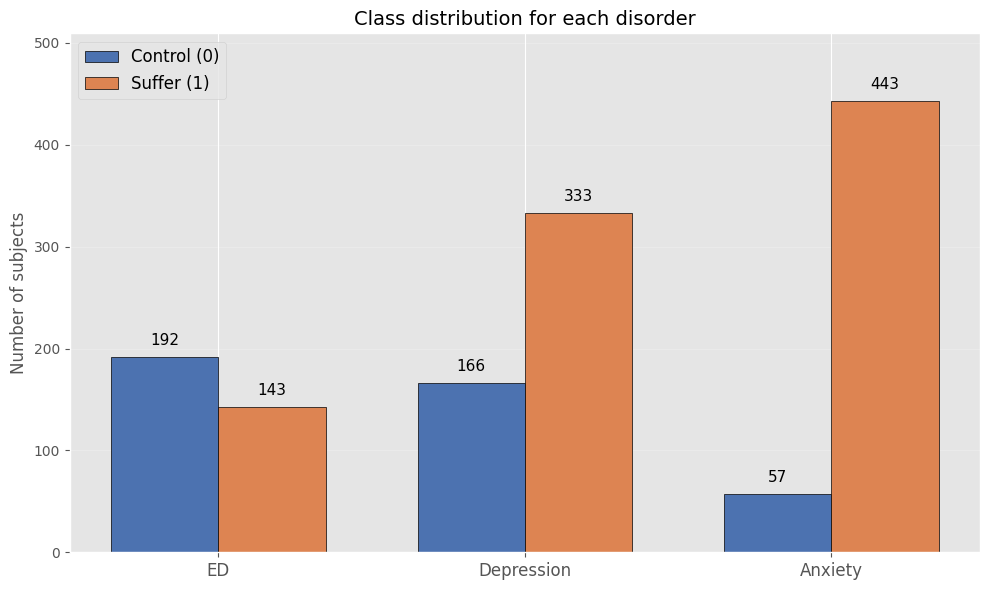

In [6]:
# Get counts
ed_counts = df_ed['bs'].value_counts()
dep_counts = df_dep['bs'].value_counts()
anx_counts = df_anx['bs'].value_counts()

# Disorder names
labels = ["ED", "Depression", "Anxiety"]

# Sorted values: for each disorder -> [control, suffer]
control_vals = [ed_counts[0], dep_counts[0], anx_counts[0]]
suffer_vals  = [ed_counts[1], dep_counts[1], anx_counts[1]]

x = np.arange(len(labels))         # base positions
width = 0.35                       # width of each bar

plt.style.use('ggplot')  # modern style

plt.figure(figsize=(10,6))

# Professional colors
color_control = "#4C72B0"  # soft blue
color_suffer  = "#DD8452"  # soft orange

# Bars: control
bars1 = plt.bar(x - width/2, control_vals, width,
                label="Control (0)", color=color_control, edgecolor="black")

# Bars: suffer
bars2 = plt.bar(x + width/2, suffer_vals, width,
                label="Suffer (1)", color=color_suffer, edgecolor="black")

# Add values on top of each bar
for bar in bars1 + bars2:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        yval + max(control_vals + suffer_vals)*0.02,
        str(yval),
        ha='center', va='bottom', fontsize=11
    )

# Aesthetic configuration
plt.xticks(x, labels, fontsize=12)
plt.ylabel("Number of subjects", fontsize=12)
plt.title("Class distribution for each disorder", fontsize=14)

plt.grid(axis='y', alpha=0.2)
plt.ylim(0, max(control_vals + suffer_vals) * 1.15)
plt.legend(fontsize=12)

plt.tight_layout()
plt.show()

# PART 2: Analysis of number of messages per user

## 2.1. Auxiliary functions

In [7]:
import json
from tqdm import tqdm

def load_json_messages(folder_path):
    """
    Returns a dictionary:
    { user_id : [list_of_messages] }
    """
    messages = {}
    for filename in os.listdir(folder_path):
        if filename.endswith(".json"):
            user_id = filename.replace(".json", "")
            with open(os.path.join(folder_path, filename), "r", encoding="utf-8") as f:
                data = json.load(f)
                messages[user_id] = [m["message"] for m in data]
    return messages

def count_messages_and_words(user_messages):
    """
    Returns a dictionary with:
    { user_id : (num_messages, num_words) }
    """
    stats = {}
    for user_id, messages in user_messages.items():
        num_messages = len(messages)
        num_words = sum(len(m.split()) for m in messages)
        stats[user_id] = (num_messages, num_words)
    return stats

## 2.2. Process number of messages and words for each disorder

In [8]:
def analyze_disorder_messages(df, json_path):
    """
    Analyzes the number of messages and words per user for a specific disorder.

    Parameters:
        df (DataFrame): dataframe with users and their 'bs' label.
        json_path (str): path to the folder with JSON files of each user.

    Returns:
        DataFrame: table with columns
                   ['user_id', 'bs', 'num_messages', 'num_words'].
    """

    # Load messages
    messages = load_json_messages(json_path)

    # Count messages and words
    stats = count_messages_and_words(messages)

    # Create intermediate dataframe
    data = []
    for user_id, (num_messages, num_words) in stats.items():
        if user_id in df["nick"].values:
            label = int(df[df["nick"] == user_id]["bs"].iloc[0])
            data.append([user_id, label, num_messages, num_words])

    df_stats = pd.DataFrame(data, columns=["user_id", "bs", "num_messages", "num_words"])

    return df_stats

stats_anx = analyze_disorder_messages(df_anx, paths["Anxiety"]["json"])
stats_dep = analyze_disorder_messages(df_dep, paths["Depression"]["json"])
stats_ed = analyze_disorder_messages(df_ed, paths["ED"]["json"])

## 2.3. Summarize statistics

In [9]:
def summarize_disorder_stats(df_stats):
    """
    Creates a table with:
    rows -> metrics
    columns -> Control / Suffer / Total
    """
    # Separate groups
    df_control = df_stats[df_stats["bs"] == 0]
    df_suffer  = df_stats[df_stats["bs"] == 1]

    summary = {
        "Control": {
            "num_subjects": len(df_control),
            "num_messages": df_control["num_messages"].sum(),
            "avg_messages": df_control["num_messages"].mean(),
            "num_words": df_control["num_words"].sum(),
            "avg_words": df_control["num_words"].mean(),
        },
        "Suffer": {
            "num_subjects": len(df_suffer),
            "num_messages": df_suffer["num_messages"].sum(),
            "avg_messages": df_suffer["num_messages"].mean(),
            "num_words": df_suffer["num_words"].sum(),
            "avg_words": df_suffer["num_words"].mean(),
        },
        "Total": {
            "num_subjects": len(df_stats),
            "num_messages": df_stats["num_messages"].sum(),
            "avg_messages": df_stats["num_messages"].mean(),
            "num_words": df_stats["num_words"].sum(),
            "avg_words": df_stats["num_words"].mean(),
        }
    }

    # Convert dictionary to DataFrame
    summary_table = pd.DataFrame(summary)

    return summary_table.round(2)

display(summarize_disorder_stats(stats_anx))
print("\n")
display(summarize_disorder_stats(stats_dep))
print("\n")
display(summarize_disorder_stats(stats_ed))

,Control,Suffer,Total
num_subjects,57.00,443.00,500.00
num_messages,2222.00,16293.00,18515.00
avg_messages,38.98,36.78,37.03
num_words,31248.00,276853.00,308101.00
avg_words,548.21,624.95,616.20


,Control,Suffer,Total
num_subjects,166.00,333.00,499.00
num_messages,6287.00,11083.00,17370.00
avg_messages,37.87,33.28,34.81
num_words,84435.00,159868.00,244303.00
avg_words,508.64,480.08,489.59


,Control,Suffer,Total
num_subjects,192.00,143.00,335.00
num_messages,6586.00,3913.00,10499.00
avg_messages,34.30,27.36,31.34
num_words,93614.00,64667.00,158281.00
avg_words,487.57,452.22,472.48
